<a href="https://colab.research.google.com/github/D2718281828nis/ML-MachineLearning-Graphs/blob/main/research-notebooks/Graph%20from%20DataFrame%20tSNE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Audit note (2026-11).** This notebook was corrected after the case study
> [ML-overlay-problem](https://github.com/D2718281828nis/ML-overlay-problem) found four problems,
> and it was re-run top to bottom after the fixes:
>
> 1. **Label leakage in the graph.** The old graph had *only* "type-based edges", which join points
>    with the same `Type`. `Type` is the colour (cross = green, point = red), so the graph's
>    components were the classes. Edges are now a label-free k-NN graph; the leaky variant is kept
>    behind `USE_TYPE_EDGES = False` for comparison.
> 2. **Invalid t-SNE test set.** t-SNE has no `transform`: fitting it separately on the train and test
>    points gives two unrelated maps. t-SNE is now fitted once on all points (it never sees the
>    colours) and the classifier is scored with stratified 5-fold cross-validation.
> 3. **Class imbalance.** Red is 13.6% of the points. The old classifier predicted no red point
>    (accuracy 0.81, F1 = 0). The forest now uses `class_weight="balanced"` and the report shows F1
>    for red next to the all-red baseline F1 = 2p/(1+p) = 0.239.
> 4. **Broken data path and plot.** The download saved `red_green_overlay.csv` but the code read
>    `df_red_green_overlay.csv`; the perplexity plot mixed two embeddings (`X_tsne[mask, 1]`).
>
> **Result after the fix** (re-run 2026-11, CPU): F1 (red) = 0.43 for a balanced forest on (X, Y)
> and 0.42 on the t-SNE map, against the 0.239 baseline: t-SNE adds nothing. In the label-free
> k-NN graph only 33% of a red node's edges lead to red, so message passing mixes the classes.
>
> A worked example of when a k-NN graph *does* separate the classes is
> [`examples/graph_connectivity_chains_circles.ipynb`](../examples/graph_connectivity_chains_circles.ipynb).

https://github.com/digailab/awesome-hyperbolic-graph-learning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Load dataset

In [2]:
# Load the data from this repository (local clone or GitHub when running on Colab)
DATA = "df_red_green_overlay.csv"
RAW = "https://raw.githubusercontent.com/D2718281828nis/ML-MachineLearning-Graphs/main/datasets/"
local = next((p / DATA for p in (Path("../datasets"), Path("datasets")) if (p / DATA).exists()), None)
df = pd.read_csv(local if local is not None else RAW + DATA)
print(df.shape, "loaded from", local or RAW + DATA)

(1672, 4) loaded from ../datasets/df_red_green_overlay.csv


In [3]:
# Type is redundant with Color (cross = green, point = red): never use it as a feature or for edges
print(pd.crosstab(df['Color'], df['Type']))

Type         cross  point
Color                    
light_green   1445      0
red              0    227


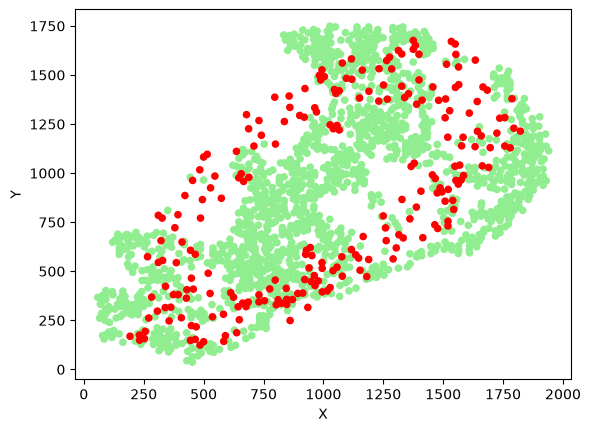

In [4]:
df.plot.scatter(x='X', y='Y', c=df['Color'].map({'light_green': 'lightgreen', 'red': 'red'}))
plt.show()

# t-SNE and RandomForestClassifier

n = 1672, red = 227 (13.6%), all-red baseline F1 = 0.239



=== Random forest on X, Y (5-fold CV) ===
              precision    recall  f1-score   support

       green      0.936     0.779     0.850      1445
         red      0.319     0.661     0.430       227

    accuracy                          0.763      1672
   macro avg      0.628     0.720     0.640      1672
weighted avg      0.852     0.763     0.793      1672

Confusion matrix [rows = true green/red]:
 [[1125  320]
 [  77  150]]



=== Random forest on t-SNE map (5-fold CV) ===
              precision    recall  f1-score   support

       green      0.935     0.768     0.843      1445
         red      0.309     0.661     0.421       227

    accuracy                          0.754      1672
   macro avg      0.622     0.714     0.632      1672
weighted avg      0.850     0.754     0.786      1672

Confusion matrix [rows = true green/red]:
 [[1110  335]
 [  77  150]]


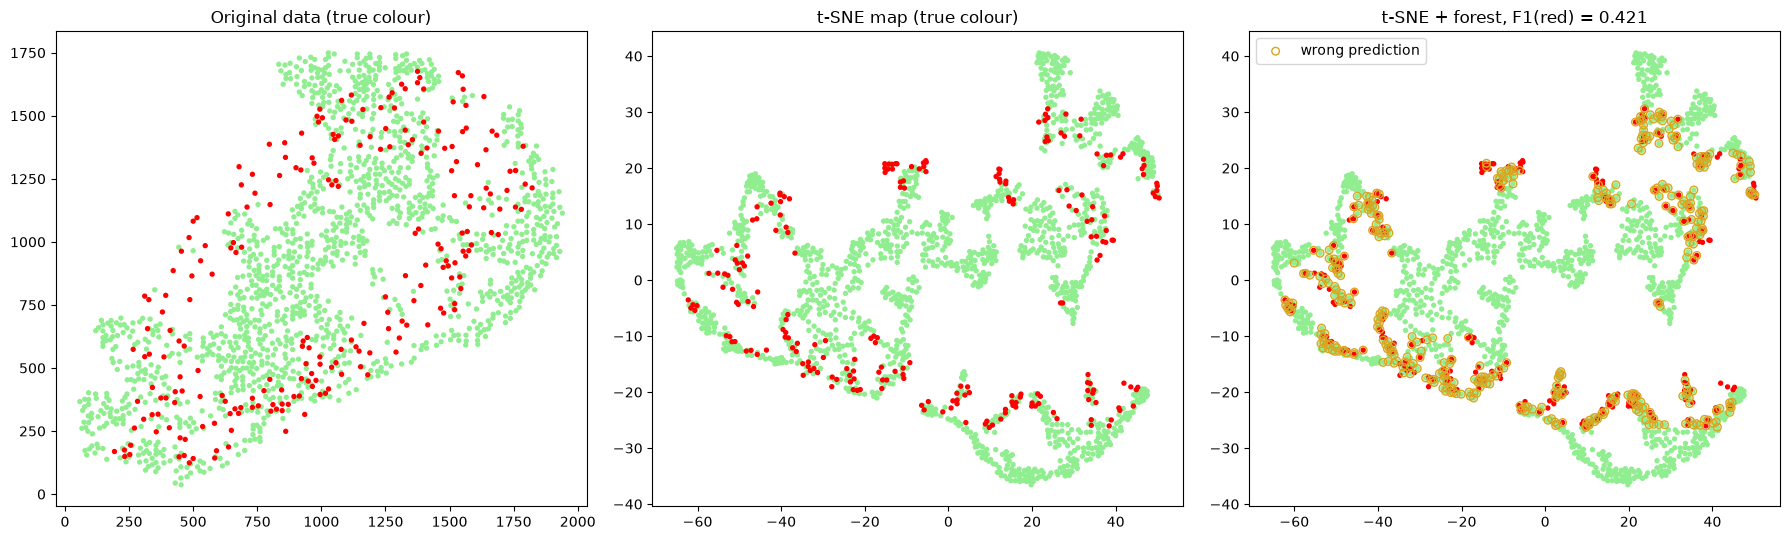

In [5]:
# Features are the coordinates only; the colour is the target (1 = red, the minority class)
X = df[['X', 'Y']].to_numpy(float)
y = (df['Color'] == 'red').to_numpy(int)
p = y.mean()
print(f"n = {len(y)}, red = {y.sum()} ({p:.1%}), all-red baseline F1 = {2 * p / (1 + p):.3f}")

# t-SNE is transductive (no transform for new points): fit it ONCE on all points.
# It never sees the colours, so the map itself does not leak the labels.
X_tsne = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(X)

# Score a class-balanced random forest with stratified 5-fold CV (every point predicted out of fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
forest = RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=5, random_state=42)
results = {}
for name, features in {"X, Y": X, "t-SNE map": X_tsne}.items():
    pred = cross_val_predict(forest, features, y, cv=cv)
    results[name] = pred
    print(f"\n=== Random forest on {name} (5-fold CV) ===")
    print(classification_report(y, pred, target_names=['green', 'red'], digits=3))
    print("Confusion matrix [rows = true green/red]:\n", confusion_matrix(y, pred))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
col = np.where(y == 1, 'red', 'lightgreen')
axes[0].scatter(X[:, 0], X[:, 1], c=col, s=8)
axes[0].set_title('Original data (true colour)')
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=col, s=8)
axes[1].set_title('t-SNE map (true colour)')
wrong = results['t-SNE map'] != y
axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=col, s=8)
axes[2].scatter(X_tsne[wrong, 0], X_tsne[wrong, 1], facecolors='none', edgecolors='goldenrod', s=30, label='wrong prediction')
axes[2].set_title(f"t-SNE + forest, F1(red) = {f1_score(y, results['t-SNE map']):.3f}")
axes[2].legend()
plt.tight_layout()
plt.show()

In [6]:
from time import time
import numpy as np
from sklearn import manifold
from matplotlib.ticker import NullFormatter


perplexity=3 in 0.43 sec


perplexity=5 in 0.43 sec


perplexity=7 in 0.42 sec


perplexity=10 in 0.4 sec


perplexity=20 in 0.45 sec


perplexity=30 in 0.49 sec


perplexity=40 in 0.52 sec


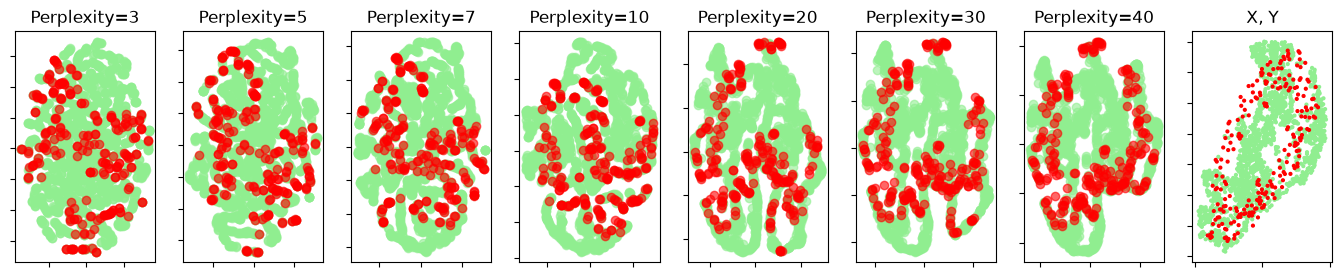

In [7]:
n_components = 2
perplexities = [3, 5, 7, 10, 20, 30, 40]


(fig, subplots) = plt.subplots(1, len(perplexities)+1, figsize=(17, 3))


for idx, perplexity in enumerate(perplexities):
    ax = subplots[idx]

    t0 = time()
    tsne = manifold.TSNE(
        n_components=n_components,
        init="random",
        random_state=0,
        perplexity=perplexity,
        max_iter=300,
    )
    X_tsne_perplx = tsne.fit_transform(X/np.std(X))
    t1 = time()
    print("perplexity=%d in %.2g sec" % (perplexity, t1 - t0))
    ax.set_title("Perplexity=%d" % perplexity)

    unique_labels = [0, 1]
    colors = ['lightgreen', 'red']   # y: 0 = green, 1 = red
    for i, label in enumerate(unique_labels):
      mask = y == label
      ax.scatter(X_tsne_perplx[mask, 0], X_tsne_perplx[mask, 1],
                 c=colors[i], label=label, alpha=0.6)

    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")

# Last panel: the original coordinates for comparison
ax = subplots[-1]
ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, 'red', 'lightgreen'), s=4)
ax.set_title("X, Y")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
plt.show()

# Graph representation

In [8]:
import networkx as nx
from sklearn.neighbors import NearestNeighbors

In [9]:
# Nodes carry the coordinates; Color and Type are kept only to colour the plots
G = nx.Graph()
for idx, row in df.iterrows():
    G.add_node(idx, pos=(row['X'], row['Y']), color=row['Color'], type=row['Type'], x=row['X'], y=row['Y'])
print(f"Graph created with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges")

Graph created with 1672 nodes and 0 edges


In [10]:
# Method 1 (label-free): connect every point to its K nearest neighbours in (X, Y)
K = 10
nn = NearestNeighbors(n_neighbors=K + 1).fit(X)
dist, nbr = nn.kneighbors(X)
for i in range(len(X)):
    for d, j in zip(dist[i, 1:], nbr[i, 1:]):
        G.add_edge(i, int(j), weight=float(d), type_based=False)
print(f"k-NN graph (k = {K}): {G.number_of_edges()} edges")

# Method 2 (LEAKS THE LABEL, off by default): extra edges between points of the same Type.
# Type is the colour, so these edges hand the answer to any graph method. Kept only to show the effect.
USE_TYPE_EDGES = False
if USE_TYPE_EDGES:
    same_type_edges = 0
    for i, j in zip(*np.triu_indices(len(df), 1)):
        if df['Type'].iat[i] == df['Type'].iat[j] and not G.has_edge(i, j) and np.hypot(*(X[i] - X[j])) < 100:
            G.add_edge(int(i), int(j), weight=float(np.hypot(*(X[i] - X[j]))), type_based=True)
            same_type_edges += 1
    print(f"WARNING: added {same_type_edges} type-based edges -> label leakage")

# Edge homophily: how often an edge joins points of the same colour (diagnostic only)
same = np.mean([G.nodes[u]['color'] == G.nodes[v]['color'] for u, v in G.edges()])
red_nodes = [n for n in G if G.nodes[n]['color'] == 'red']
red_red = np.mean([G.nodes[v]['color'] == 'red' for n in red_nodes for v in G[n]])
print(f"Edge homophily: {same:.3f};  share of a red node's edges that lead to red: {red_red:.3f}")
print(f"Average degree: {2 * G.number_of_edges() / G.number_of_nodes():.2f}")

k-NN graph (k = 10): 9675 edges
Edge homophily: 0.822;  share of a red node's edges that lead to red: 0.327
Average degree: 11.57


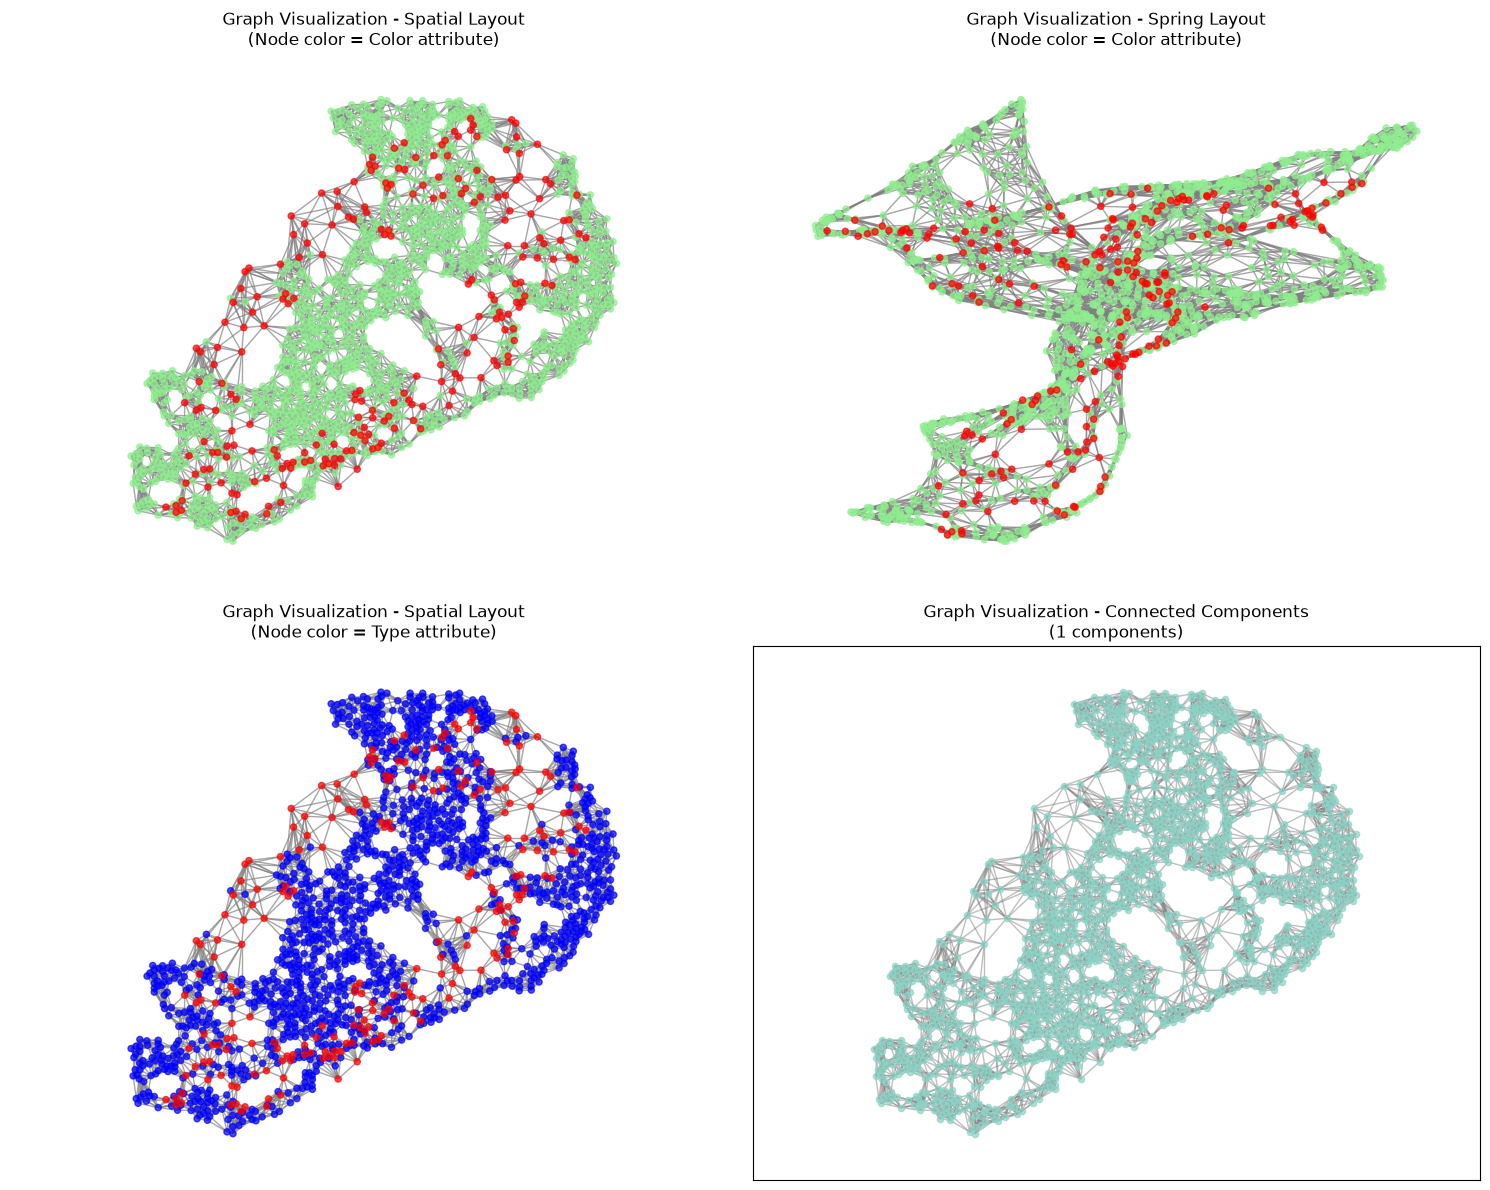


GRAPH ANALYSIS
Number of connected components: 1
Component sizes: [1672]
Largest component size: 1672
Smallest component size: 1672

Degree statistics:
  Max degree: 19
  Min degree: 10
  Average degree: 11.57

Color-based analysis:
  light_green: 1445 nodes, avg degree: 11.62
  red: 227 nodes, avg degree: 11.27

Type-based analysis:
  cross: 1445 nodes, avg degree: 11.62
  point: 227 nodes, avg degree: 11.27


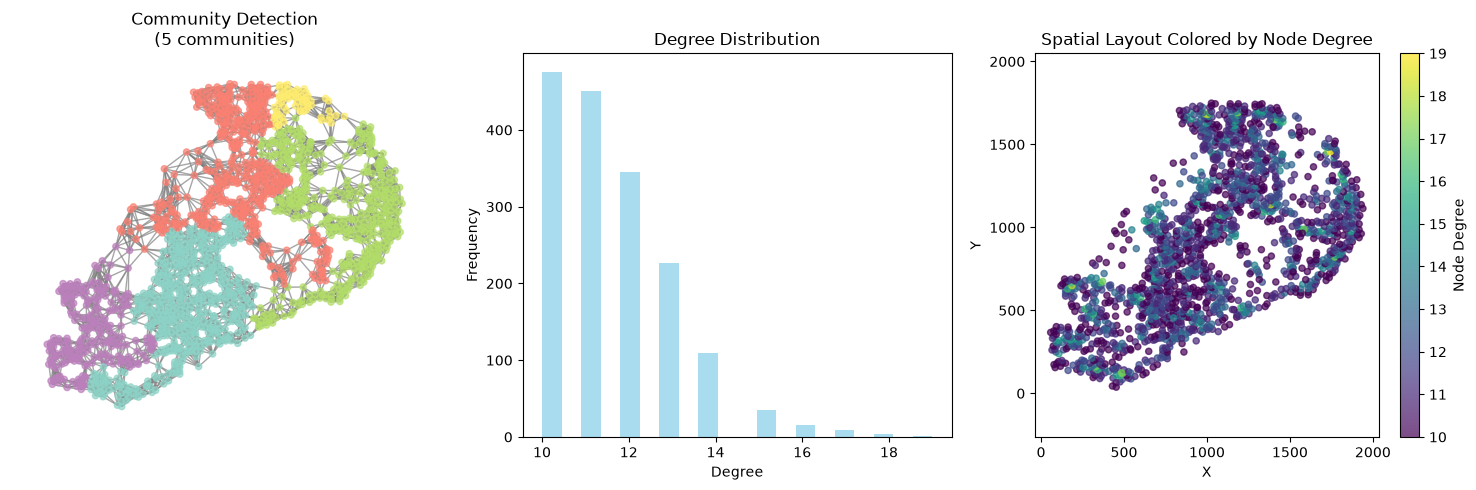


Graph exported with 1672 nodes and 9675 edges
Node attributes: pos, color, type, x, y
Edge attributes: weight, type_based (True only if USE_TYPE_EDGES)


In [11]:



# Visualization 1: Basic graph layout
plt.figure(figsize=(15, 12))

# Get node colors for plotting
node_colors = [G.nodes[node]['color'] for node in G.nodes()]
# Map color names to actual colors
color_map = {'light_green': 'lightgreen', 'red': 'red'}
mapped_colors = [color_map[color] for color in node_colors]

# Get positions from node attributes
pos = {node: (G.nodes[node]['x'], G.nodes[node]['y']) for node in G.nodes()}

plt.subplot(2, 2, 1)
nx.draw(G, pos, node_color=mapped_colors, node_size=20,
       edge_color='gray', alpha=0.7, with_labels=False)
plt.title('Graph Visualization - Spatial Layout\n(Node color = Color attribute)')
plt.axis('equal')

# Visualization 2: Spring layout
plt.subplot(2, 2, 2)
spring_pos = nx.spring_layout(G, k=0.3, iterations=50)
nx.draw(G, spring_pos, node_color=mapped_colors, node_size=20,
       edge_color='gray', alpha=0.7, with_labels=False)
plt.title('Graph Visualization - Spring Layout\n(Node color = Color attribute)')

# Visualization 3: Color by Type
plt.subplot(2, 2, 3)
type_colors = ['blue' if G.nodes[node]['type'] == 'cross' else 'red' for node in G.nodes()]
nx.draw(G, pos, node_color=type_colors, node_size=20,
       edge_color='gray', alpha=0.7, with_labels=False)
plt.title('Graph Visualization - Spatial Layout\n(Node color = Type attribute)')
plt.axis('equal')

# Visualization 4: Highlight connected components
plt.subplot(2, 2, 4)
connected_components = list(nx.connected_components(G))
colors = plt.cm.Set3(np.linspace(0, 1, len(connected_components)))

for i, component in enumerate(connected_components):
    nx.draw_networkx_nodes(G, pos, nodelist=list(component),
                          node_color=[colors[i]], node_size=20, alpha=0.7)

nx.draw_networkx_edges(G, pos, edge_color='gray', alpha=0.5)
plt.title(f'Graph Visualization - Connected Components\n({len(connected_components)} components)')
plt.axis('equal')

plt.tight_layout()
plt.show()

# Additional analysis
print("\n" + "="*50)
print("GRAPH ANALYSIS")
print("="*50)

# Connected components analysis
print(f"Number of connected components: {len(connected_components)}")
component_sizes = [len(comp) for comp in connected_components]
print(f"Component sizes: {component_sizes}")
print(f"Largest component size: {max(component_sizes)}")
print(f"Smallest component size: {min(component_sizes)}")

# Degree analysis
degrees = [degree for node, degree in G.degree()]
print(f"\nDegree statistics:")
print(f"  Max degree: {max(degrees)}")
print(f"  Min degree: {min(degrees)}")
print(f"  Average degree: {np.mean(degrees):.2f}")

# Color-based analysis
print(f"\nColor-based analysis:")
for color in ['light_green', 'red']:
    color_nodes = [node for node in G.nodes() if G.nodes[node]['color'] == color]
    avg_degree = np.mean([G.degree(node) for node in color_nodes])
    print(f"  {color}: {len(color_nodes)} nodes, avg degree: {avg_degree:.2f}")

# Type-based analysis
print(f"\nType-based analysis:")
for node_type in ['cross', 'point']:
    type_nodes = [node for node in G.nodes() if G.nodes[node]['type'] == node_type]
    avg_degree = np.mean([G.degree(node) for node in type_nodes])
    print(f"  {node_type}: {len(type_nodes)} nodes, avg degree: {avg_degree:.2f}")

# Advanced visualization: Community detection
plt.figure(figsize=(15, 5))

# Try to detect communities
try:
    from networkx.algorithms import community

    # Use greedy modularity communities
    communities = community.greedy_modularity_communities(G)

    plt.subplot(1, 3, 1)
    # Color nodes by community
    community_colors = []
    for node in G.nodes():
        for i, comm in enumerate(communities):
            if node in comm:
                community_colors.append(i)
                break

    nx.draw(G, pos, node_color=community_colors, node_size=20,
           cmap=plt.cm.Set3, edge_color='gray', alpha=0.7, with_labels=False)
    plt.title(f'Community Detection\n({len(communities)} communities)')
    plt.axis('equal')

except ImportError:
    print("Community detection requires additional packages")

# Degree distribution
plt.subplot(1, 3, 2)
degree_sequence = sorted([d for n, d in G.degree()], reverse=True)
plt.hist(degree_sequence, bins=20, alpha=0.7, color='skyblue')
plt.xlabel('Degree')
plt.ylabel('Frequency')
plt.title('Degree Distribution')

# Node attributes visualization
plt.subplot(1, 3, 3)
# Scatter plot of original coordinates colored by graph degree
node_degrees = [G.degree(node) for node in G.nodes()]
scatter = plt.scatter(df['X'], df['Y'], c=node_degrees, cmap='viridis',
                    alpha=0.7, s=20)
plt.colorbar(scatter, label='Node Degree')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Spatial Layout Colored by Node Degree')
plt.axis('equal')

plt.tight_layout()
plt.show()

# Export graph for further analysis (optional)
print(f"\nGraph exported with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges")
print("Node attributes: pos, color, type, x, y")
print("Edge attributes: weight, type_based (True only if USE_TYPE_EDGES)")

# Graph clustering with Gromov Wasserstein Distance

The Gromov–Wasserstein experiment continues in
[`Gromov-Waserstein graph clastering.ipynb`](Gromov-Waserstein%20graph%20clastering.ipynb).

https://github.com/trneedham/Spectral-Gromov-Wasserstein